In [47]:

from pathlib import Path
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms
import sys

sys.path.insert(0, r"C:\Users\vippu\ai-nst-project\NST_Code\utils")
from models import VGGEncoder


In [48]:

from pathlib import Path
import torch
from torchvision import transforms

ROOT = Path.cwd()
EXAMPLES = ROOT / "NST_Code" / "examples"
VGG_WEIGHTS = ROOT / "NST_Code" / "models" / "vgg_normalised.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
image_size = 512

image_paths = {
    "Original Brad Pitt": EXAMPLES / "brad_pitt.jpg",
    "Stylized Brad Pitt A": EXAMPLES / "stylized_brad_pitt.jpg",
    "Stylized Brad Pitt B": EXAMPLES / "stylized_brad_pitt (1).jpg"
}

transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
])

print("Weights file exists:", VGG_WEIGHTS.exists())
print("Examples folder exists:", EXAMPLES.exists())
print("Using device:", device)


Weights file exists: False
Examples folder exists: True
Using device: cpu


In [49]:

def load_image(path):
    image = Image.open(path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)
    return image, tensor


def show_images(paths_dict):
    fig, axes = plt.subplots(1, len(paths_dict), figsize=(16, 5))

    for ax, (title, path) in zip(axes, paths_dict.items()):
        image = Image.open(path).convert("RGB")
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def extract_features(tensor):
    with torch.no_grad():
        h1, h2, h3, h4 = encoder(tensor)

        return {
            "relu1_1": h1,
            "relu2_1": h2,
            "relu3_1": h3,
            "relu4_1": h4,
        }


def activation_map(feature_tensor):
    activation = feature_tensor[0].mean(dim=0).detach().cpu()
    activation = activation - activation.min()
    activation = activation / (activation.max() + 1e-8)
    return activation


In [38]:

image_tensors = {}
feature_bank = {}

for name, path in image_paths.items():
    _, tensor = load_image(path)
    image_tensors[name] = tensor
    feature_bank[name] = extract_features(tensor)

for name, features in feature_bank.items():
    shapes = {
        layer: tuple(feature.shape)
        for layer, feature in features.items()
    }
    print(name)
    print(shapes)
    print()


Original Brad Pitt
{'relu1_1': (1, 64, 512, 512), 'relu2_1': (1, 128, 256, 256), 'relu3_1': (1, 256, 128, 128), 'relu4_1': (1, 512, 64, 64)}

Stylized Brad Pitt A
{'relu1_1': (1, 64, 512, 512), 'relu2_1': (1, 128, 256, 256), 'relu3_1': (1, 256, 128, 128), 'relu4_1': (1, 512, 64, 64)}

Stylized Brad Pitt B
{'relu1_1': (1, 64, 512, 512), 'relu2_1': (1, 128, 256, 256), 'relu3_1': (1, 256, 128, 128), 'relu4_1': (1, 512, 64, 64)}



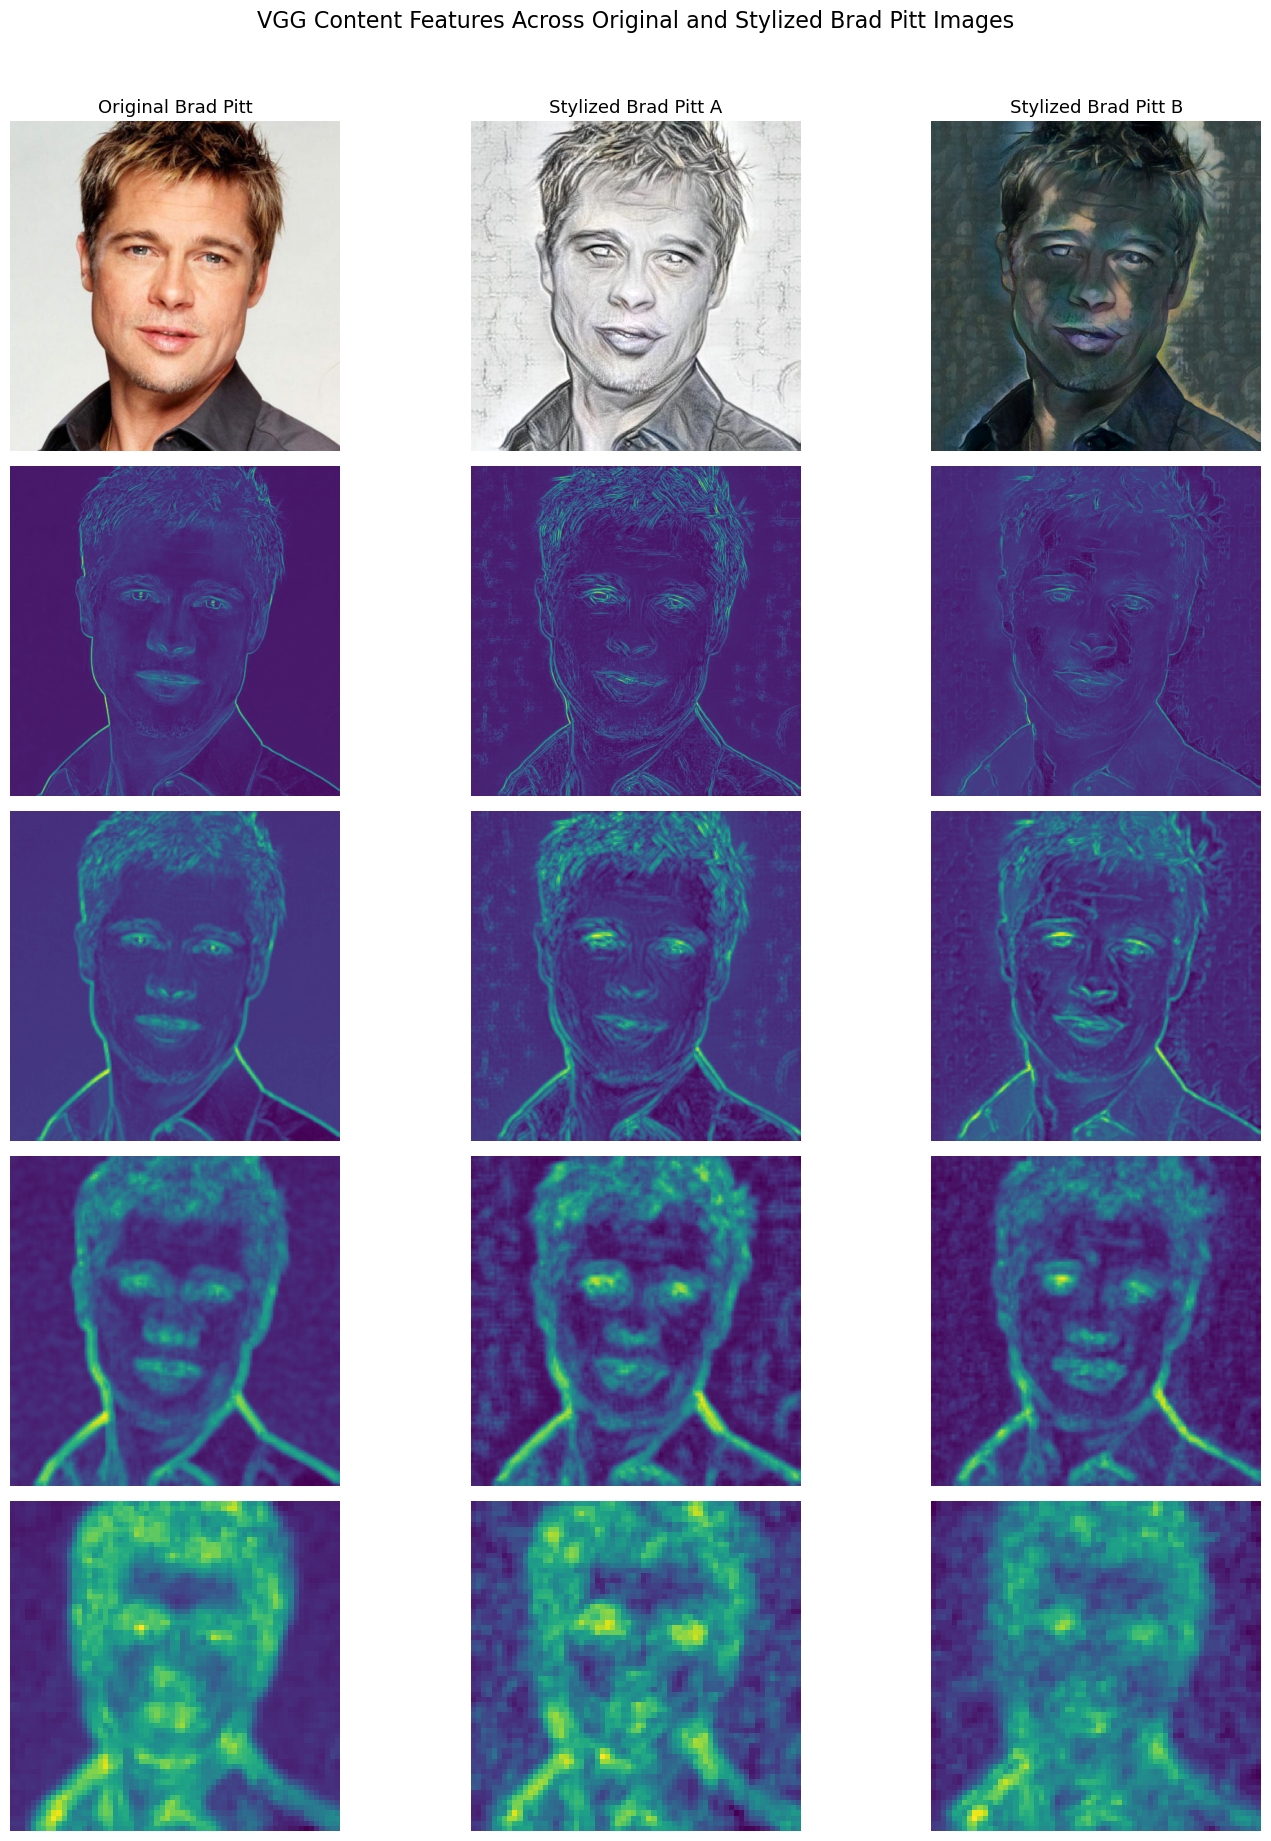

In [52]:

layers_to_show = ["relu1_1", "relu2_1", "relu3_1", "relu4_1"]
row_labels = ["Input Image"] + layers_to_show

num_rows = len(row_labels)
num_cols = len(image_paths)

fig, axes = plt.subplots(
    num_rows,
    num_cols,
    figsize=(5 * num_cols, 3.6 * num_rows),
    squeeze=False
)

for col, (name, path) in enumerate(image_paths.items()):
    # Original image
    image = Image.open(path).convert("RGB")
    axes[0, col].imshow(image)
    axes[0, col].set_title(name, fontsize=13)
    axes[0, col].axis("off")

    # Feature activation maps
    for row, layer in enumerate(layers_to_show, start=1):
        activation = activation_map(feature_bank[name][layer])
        axes[row, col].imshow(activation, cmap="viridis")
        axes[row, col].axis("off")

# Row labels
for row, label in enumerate(row_labels):
    axes[row, 0].set_ylabel(
        label,
        fontsize=12,
        rotation=90,
        labelpad=18
    )

plt.suptitle(
    "VGG Content Features Across Original and Stylized Brad Pitt Images",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()
